# Exploring FNN Performance as a function of layers 

In this notebook, we complete a simple study to see how the (best) validation accuracy of the model changes as a function of the number of layers, for 50 epochs, a batch size of 50, and a hidden dimension of 50 for each model. 

In [1]:
import sys
PYTHONPATH="../"
sys.path.append(PYTHONPATH)
import models 
from train import * 
import matplotlib.pyplot as py 
import numpy as np 
%matplotlib inline 

Using TensorFlow backend.


In [2]:
# extract the model inputs 
train_file = "../Preprocess/preprocess_outputs/train_DLP_Test.h5"
val_file = "../Preprocess/preprocess_outputs/val_DLP_Test.h5"
weight_file = "../Preprocess/preprocess_outputs/weight_DLP_Test.h5"
num_classes = 3
X_train, X_val, Y_train, Y_val, X_weights = models.fnn_input(train_file, val_file, weight_file, num_classes)

In [3]:
# main experiment loop 
num_vars = X_train.shape[1] 
layers = 20 # train 10 models, from 1 layer to 10 layers 
best_val_accuracy = [] 

for i in range(layers):
    nHidden = i + 1
    hidden_dims = np.ones(nHidden, dtype=np.int32)*50 # hidden dimension of size 50 for each layer 
    model_i = models.FNN(input_dim=num_vars, num_hidden=nHidden, hidden_dims=hidden_dims)
    history_i = fnn_train(model_i, X_train, X_val, Y_train, Y_val, X_weights, save=False, default=True)
    best_val = np.amax(history_i.history['val_acc'])
    best_val_accuracy.append(best_val)
    
    print("Best validation accuracy on iteration " + str(i + 1) + " is " + str(best_val))
    print("----------------------------------------------------")

Beginning to fit the model
Finished fitting the model, moving to next model
Best validation accuracy on iteration 1 is 0.686094068615
----------------------------------------------------
Beginning to fit the model
Finished fitting the model, moving to next model
Best validation accuracy on iteration 2 is 0.6768916135
----------------------------------------------------
Beginning to fit the model
Finished fitting the model, moving to next model
Best validation accuracy on iteration 3 is 0.694274028843
----------------------------------------------------
Beginning to fit the model
Finished fitting the model, moving to next model
Best validation accuracy on iteration 4 is 0.692229035518
----------------------------------------------------
Beginning to fit the model
Finished fitting the model, moving to next model
Best validation accuracy on iteration 5 is 0.69325153618
----------------------------------------------------
Beginning to fit the model
Finished fitting the model, moving to nex

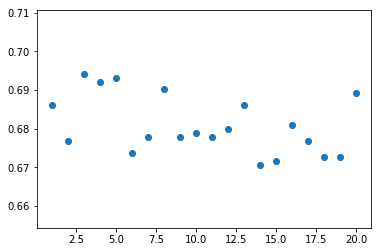

In [6]:
layers = np.arange(1, 21)
py.scatter(layers, best_val_accuracy)

In [ ]:
# there's no real correlation between validation accuracy and number of layers --> probably not training 
# on a large enough dataset 